# Impulse Response Analysis

Analysis of `RESPONSE_06-ir.wav` — exploring the time-domain waveform, frequency response, and acoustic characteristics.


In [16]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import hilbert

# Plot styling — clean, modern look
plt.rcParams.update({
    "figure.facecolor": "#fafafa",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 1.2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": "#333333",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "sans-serif",
    "grid.alpha": 0.4,
    "legend.frameon": True,
    "legend.framealpha": 0.95,
})

# Path to impulse response (notebook is in notes/, data is in data/)
IR_PATH = Path("../data/RIR.wav")


## 1. Load and inspect metadata

In [25]:
# Load impulse response (mono=True to get single channel if multi-channel)
y, sr = librosa.load(IR_PATH, sr=None, mono=False)

# Handle both mono and stereo
if y.ndim == 1:
    y = y[np.newaxis, :]
    n_channels = 1
else:
    n_channels = y.shape[0]

duration_s = y.shape[1] / sr
n_samples = y.shape[1]

print("=== Impulse Response Metadata ===")
print(f"Sample rate:     {sr} Hz")
print(f"Channels:       {n_channels}")
print(f"Samples:        {n_samples}")
print(f"Duration:       {duration_s:.4f} s ({duration_s*1000:.2f} ms)")
print(f"Shape:          {y.shape}")

print("=== Channel Statistics ===")
for ch in range(n_channels):
    samples = y[ch]
    print(f"Channel {ch+1}:")
    print(f"  Max amplitude:  {np.max(np.abs(samples)):.6f}")
    print(f"  RMS:            {np.sqrt(np.mean(samples**2)):.6f}")
    print(f"  Peak index:     {np.argmax(np.abs(samples))} (t = {np.argmax(np.abs(samples))/sr*1000:.2f} ms)")

=== Impulse Response Metadata ===
Sample rate:     48000 Hz
Channels:       1
Samples:        20944
Duration:       0.4363 s (436.33 ms)
Shape:          (1, 20944)
=== Channel Statistics ===
Channel 1:
  Max amplitude:  0.990000
  RMS:            0.039588
  Peak index:     210 (t = 4.38 ms)


## 2. Time-domain waveform

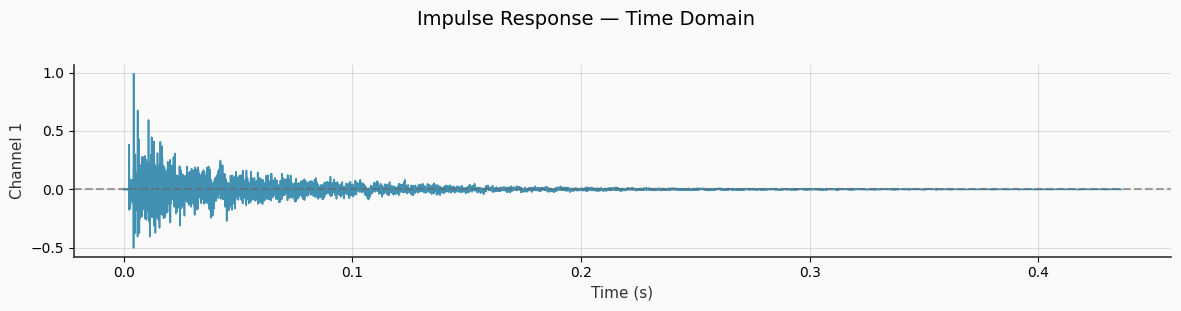

In [18]:
times = np.arange(y.shape[1]) / sr

fig, axes = plt.subplots(n_channels, 1, figsize=(12, 3 * n_channels), sharex=True)
if n_channels == 1:
    axes = [axes]

for ch, ax in enumerate(axes):
    ax.plot(times, y[ch], linewidth=1.2, color="#2E86AB", alpha=0.9)
    ax.set_ylabel(f"Channel {ch+1}")
    ax.grid(True, alpha=0.4, linestyle="-")
    ax.axhline(0, color="#666666", linestyle="--", alpha=0.6)
    ax.set_facecolor("#fafafa")

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Impulse Response — Time Domain", fontsize=14, y=1.02)
fig.patch.set_facecolor("#fafafa")
plt.tight_layout()
plt.show()

### Direct sound arrival index (time-of-flight proxy)

**What:** Sample index where the impulse "starts" (first significant energy)  
**Why:** Alignment + makes convolution/FFT results stable (and comparable across iterations)  
**How:** Find the first sample where |h[n]| exceeds a threshold (e.g. 0.01 × max|h|), or locate the max peak and search backwards to the first threshold crossing.

In [26]:
# Direct arrival: first sample exceeding threshold relative to peak
ir_channel = y[0]
h_abs = np.abs(ir_channel)
peak_idx = np.argmax(h_abs)
peak_val = h_abs[peak_idx]
threshold = 0.01 * peak_val

# Search backwards from peak to find first threshold crossing
n0 = peak_idx
for i in range(peak_idx, -1, -1):
    if h_abs[i] >= threshold:
        n0 = i
    else:
        break

t0 = n0 / sr

print("=== Direct Sound Arrival ===")
print(f"n0 (direct arrival index): {n0}")
print(f"t0 (time of flight):       {t0:.6f} s ({t0*1000:.2f} ms)")
print(f"Threshold used:           {threshold:.6f} ({0.01*100:.0f}% of peak)")

=== Direct Sound Arrival ===
n0 (direct arrival index): 205
t0 (time of flight):       0.004271 s (4.27 ms)
Threshold used:           0.009900 (1% of peak)


## 3. Frequency response (magnitude spectrum)

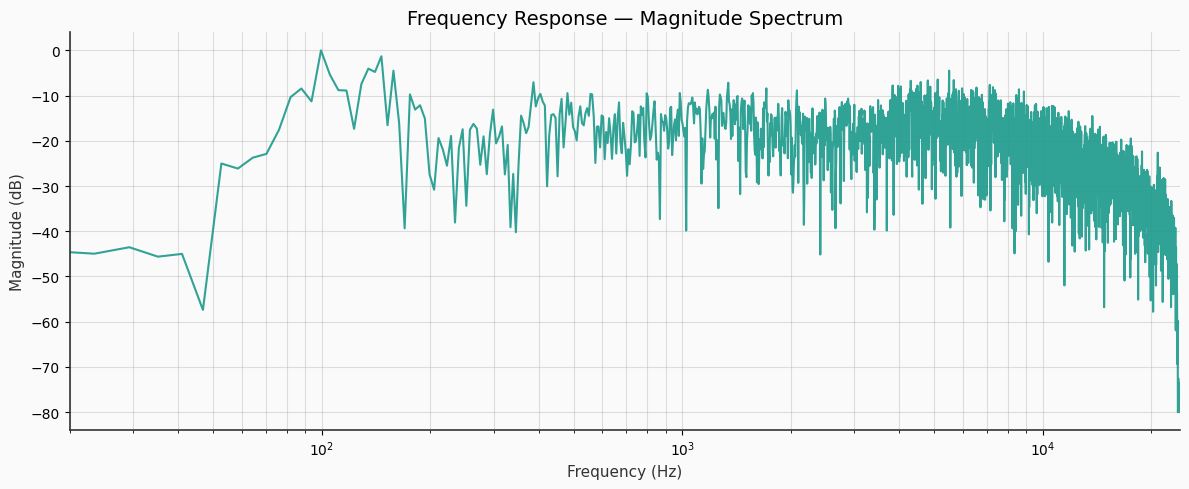

In [19]:
# Compute FFT magnitude spectrum (use first channel for multi-channel)
ir_channel = y[0]
n_fft = min(8192, len(ir_channel))
D = np.fft.rfft(ir_channel, n=n_fft)
magnitude_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
freqs = np.fft.rfftfreq(n_fft, 1 / sr)

fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogx(freqs, magnitude_db, color="#1B998B", linewidth=1.5, alpha=0.9)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_title("Frequency Response — Magnitude Spectrum")
ax.grid(True, alpha=0.4, which="both", linestyle="-")
ax.set_xlim([20, sr / 2])
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("#fafafa")
plt.tight_layout()
plt.show()

## 4. Envelope and decay

The energy envelope shows how the impulse response decays over time.

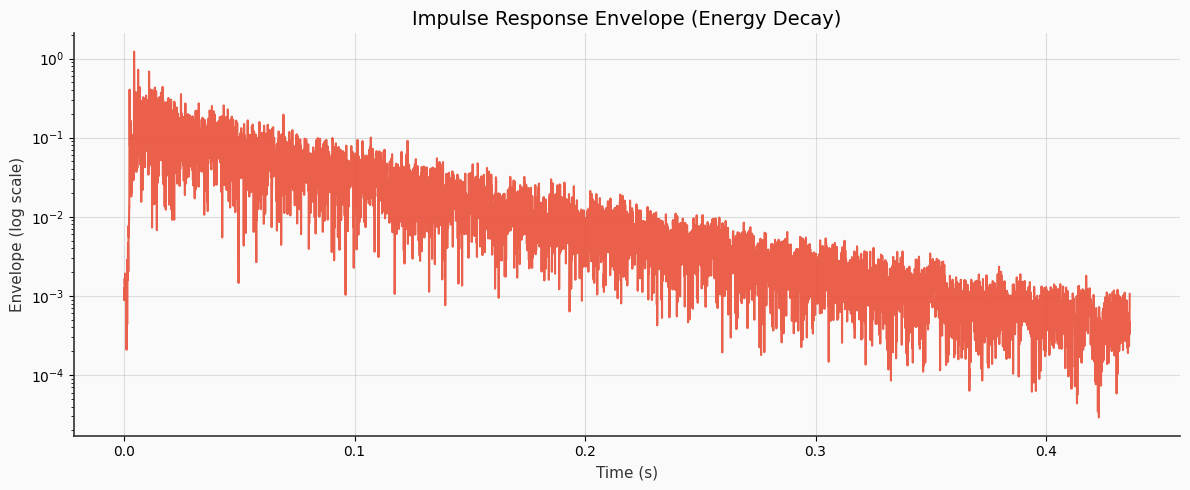

In [20]:
# Hilbert envelope (magnitude of analytic signal)
ir_channel = y[0]
envelope = np.abs(hilbert(ir_channel))

# Downsample for cleaner plot if very long
max_pts = 8000
if len(envelope) > max_pts:
    idx = np.linspace(0, len(envelope) - 1, max_pts, dtype=int)
    env_plot = envelope[idx]
    times_plot = times[idx]
else:
    env_plot = envelope
    times_plot = times

fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(times_plot, env_plot + 1e-10, color="#E94F37", linewidth=1.5, alpha=0.9)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Envelope (log scale)")
ax.set_title("Impulse Response Envelope (Energy Decay)")
ax.grid(True, alpha=0.4, linestyle="-")
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("#fafafa")
plt.tight_layout()
plt.show()

In [21]:
for ch in range(n_channels):
    samples = y[ch]
    print(f"Channel {ch+1}:")
    print(f"  Max amplitude:  {np.max(np.abs(samples)):.6f}")
    print(f"  RMS:            {np.sqrt(np.mean(samples**2)):.6f}")
    print(f"  Peak index:     {np.argmax(np.abs(samples))} (t = {np.argmax(np.abs(samples))/sr*1000:.2f} ms)")

Channel 1:
  Max amplitude:  0.990000
  RMS:            0.039588
  Peak index:     210 (t = 4.38 ms)


## 5. Frequency response comparison (all IRs)

Plot the magnitude spectrum of all impulse responses in `data/` for comparison.

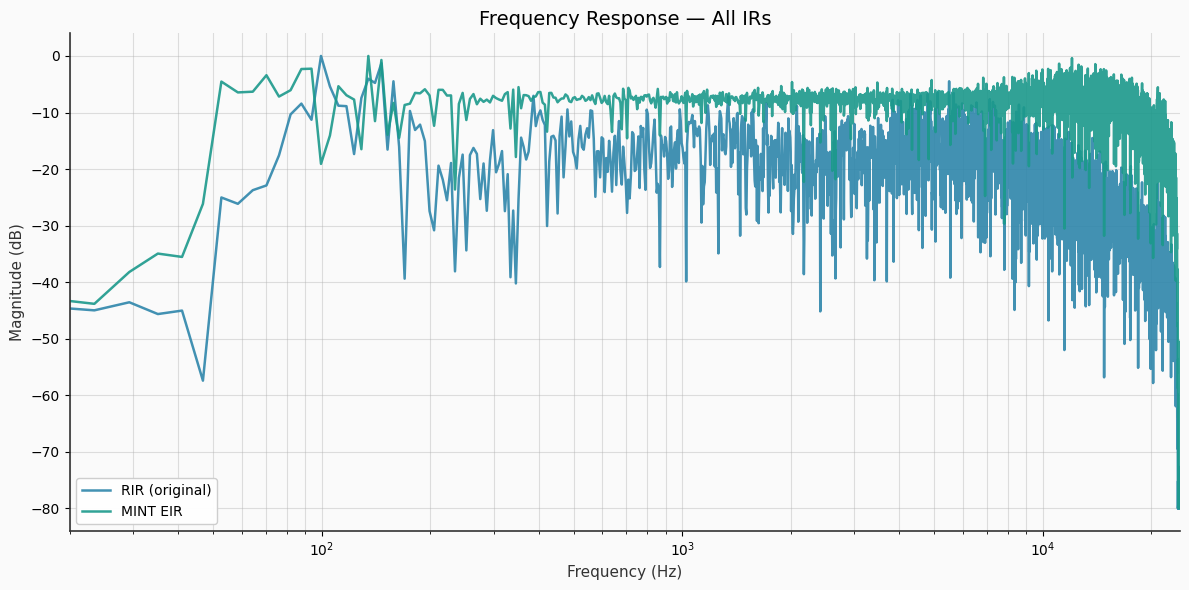

In [23]:
# All IR files in data/
DATA_DIR = Path("../data")
IR_FILES = [
    "RIR.wav",
    "MINT-EIR.wav",
   
]
LABELS = ["RIR (original)", "MINT EIR",]
COLORS = ["#2E86AB", "#1B998B", "#E94F37"]

fig, ax = plt.subplots(figsize=(12, 6))

for fname, label, color in zip(IR_FILES, LABELS, COLORS):
    path = DATA_DIR / fname
    if not path.exists():
        print(f"Skipping {fname} (not found)")
        continue
    y_ir, sr_ir = librosa.load(path, sr=None, mono=True)
    n_fft = min(8192, len(y_ir))
    D = np.fft.rfft(y_ir, n=n_fft)
    magnitude_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    freqs = np.fft.rfftfreq(n_fft, 1 / sr_ir)
    ax.semilogx(freqs, magnitude_db, label=label, color=color, linewidth=1.8, alpha=0.9)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_title("Frequency Response — All IRs")
ax.set_xlim([20, 24000])
ax.grid(True, alpha=0.4, which="both", linestyle="-")
ax.legend(loc="lower left", fontsize=10)
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("#fafafa")
plt.tight_layout()
plt.show()